## Common imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.datasets import load_iris

sns.set_theme(style="whitegrid")
np.random.seed(42)
print("Libraries imported successfully")

Libraries imported successfully


# Experiment 1(a): Analyze the trend of data science job postings
**Objective:** Use pandas and matplotlib to analyze yearly job-posting trends.

    Year  Job Postings
0   2010           150
1   2011           300
2   2012           450
3   2013           600
4   2014           800
5   2015          1200
6   2016          1600
7   2017          2100
8   2018          2700
9   2019          3400
10  2020          4200


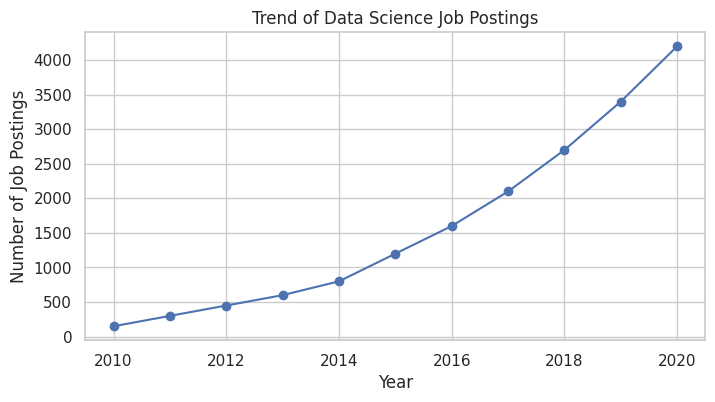

In [2]:
data = {
    'Year': list(range(2010, 2021)),
    'Job Postings': [150, 300, 450, 600, 800, 1200, 1600, 2100, 2700, 3400, 4200]
}
df_jobs = pd.DataFrame(data)
print(df_jobs)
plt.figure(figsize=(8, 4))
plt.plot(df_jobs['Year'], df_jobs['Job Postings'], marker='o')
plt.title('Trend of Data Science Job Postings')
plt.xlabel('Year')
plt.ylabel('Number of Job Postings')
plt.grid(True)
plt.show()

# Experiment 1(b): Distribution of data science roles
**Objective:** Categorize job roles and visualize their distribution.

               Role  Count
0      Data Analyst    300
1     Data Engineer    500
2    Data Scientist    450
3       ML Engineer    200
4  Business Analyst    150


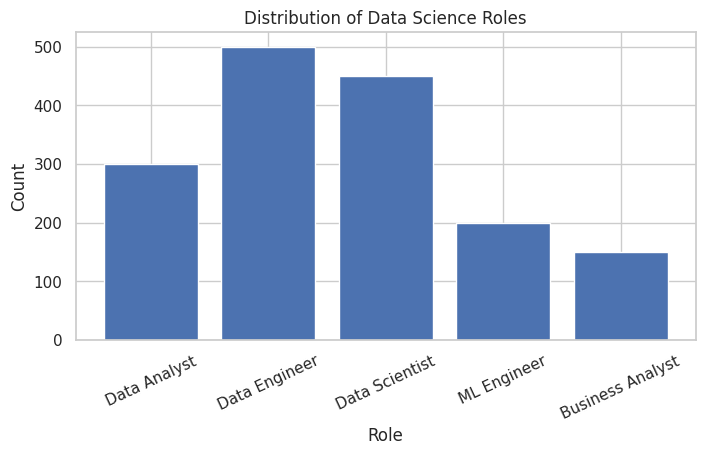

In [3]:
roles = ['Data Analyst', 'Data Engineer', 'Data Scientist', 'ML Engineer', 'Business Analyst']
counts = [300, 500, 450, 200, 150]
role_df = pd.DataFrame({'Role': roles, 'Count': counts})
print(role_df)
plt.figure(figsize=(8, 4))
plt.bar(role_df['Role'], role_df['Count'])
plt.title('Distribution of Data Science Roles')
plt.xlabel('Role')
plt.ylabel('Count')
plt.xticks(rotation=25)
plt.show()

# Experiment 1(c): Structured, unstructured and semi-structured data
**Objective:** Differentiate the three data types using examples.

In [4]:
# Structured data: rows and columns
structured_data = pd.DataFrame({
    'ID': [1, 2, 3],
    'Name': ['Alice', 'Bob', 'Charlie'],
    'Age': [25, 30, 35]
})
print("STRUCTURED DATA")
display(structured_data)

# Unstructured data: free text
unstructured_data = "This is unstructured data. It may be text, an image, audio or video."
print("\nUNSTRUCTURED DATA")
print(unstructured_data)

# Semi-structured data: JSON-like nested dictionary
semi_structured_data = {
    'ID': 1, 'Name': 'Alice',
    'Attributes': {'Height': 165, 'Weight': 68}
}
print("\nSEMI-STRUCTURED DATA")
print(semi_structured_data)

STRUCTURED DATA


,ID,Name,Age
0,1,Alice,25
1,2,Bob,30
2,3,Charlie,35



UNSTRUCTURED DATA
This is unstructured data. It may be text, an image, audio or video.

SEMI-STRUCTURED DATA
{'ID': 1, 'Name': 'Alice', 'Attributes': {'Height': 165, 'Weight': 68}}


# Experiment 1(d): Encrypt and decrypt sensitive data using Fernet
**Objective:** Encrypt plaintext and decrypt it using the generated key.

In [5]:
from cryptography.fernet import Fernet

key = Fernet.generate_key()
cipher = Fernet(key)
plain_text = b"Rajalakshmi Engineering College"
encrypted_text = cipher.encrypt(plain_text)
decrypted_text = cipher.decrypt(encrypted_text)

print("Original Data:", plain_text)
print("Encrypted Data:", encrypted_text)
print("Decrypted Data:", decrypted_text)

Original Data: b'Rajalakshmi Engineering College'
Encrypted Data: b'gAAAAABq5xwamG8XhxoMzAfmv3dlTzWab5WovfdAFvokJ48Nyr60rlB8MhCIO5wSTw0EsEi5076ahdVwEJCnJMECZuhiSkX9GAmg4Nj2irHxbinpNeeFYW4='
Decrypted Data: b'Rajalakshmi Engineering College'


# Experiment 2: Upload and analyze a CSV dataset; preprocessing and visualization
**Colab adaptation:** Instead of uploading a CSV, this cell creates a sample sales dataset and saves it as `sales_data.csv`. The remaining code reads that CSV exactly as a normal uploaded file.

First five rows:


,Date,Product,Sales,Quantity,Region
0,2023-01-01,Product A,200.0,4,North
1,2023-01-02,Product B,150.0,3,South
2,2023-01-03,Product A,220.0,5,North
3,2023-01-04,Product C,NaN,6,East
4,2023-01-05,Product A,180.0,4,West


Missing values:
Date        0
Product     0
Sales       1
Quantity    0
Region      0
dtype: int64
Summary statistics:


,Sales,Quantity
count,16.000000,16.000000
mean,242.000000,5.312500
std,59.688078,1.621471
min,150.000000,3.000000
25%,197.500000,4.000000
50%,235.000000,5.000000
75%,287.500000,6.250000
max,340.000000,8.000000


,Product,Sales,Quantity
0,Product A,1860.0,40
1,Product B,790.0,16
2,Product C,1222.0,29


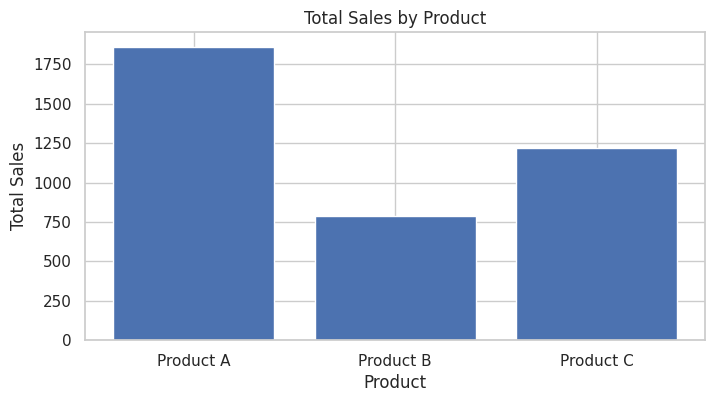

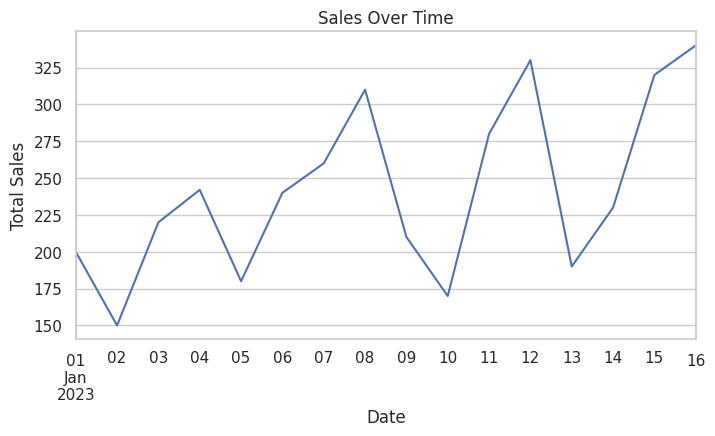

Pivot table:


Product,Product A,Product B,Product C
Region,,,
East,0.0,0.0,1222.0
North,1490.0,0.0,0.0
South,0.0,790.0,0.0
West,370.0,0.0,0.0


Correlation matrix:


,Sales,Quantity
Sales,1.000000,0.979516
Quantity,0.979516,1.000000


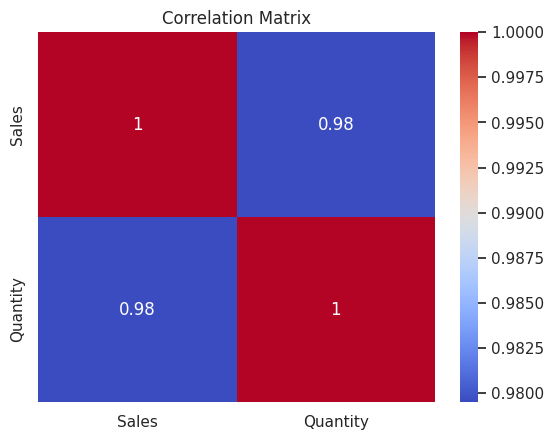

In [6]:
sales_data = pd.DataFrame({
    'Date': pd.date_range('2023-01-01', periods=16, freq='D'),
    'Product': ['Product A','Product B','Product A','Product C'] * 4,
    'Sales': [200,150,220,300,180,240,260,310,210,170,280,330,190,230,320,340],
    'Quantity': [4,3,5,6,4,5,6,7,4,3,6,8,4,5,7,8],
    'Region': ['North','South','North','East','West','South','North','East'] * 2
})
sales_data.loc[3, 'Sales'] = np.nan
sales_data.to_csv('sales_data.csv', index=False)

df = pd.read_csv('sales_data.csv')
print("First five rows:")
display(df.head())
print("Missing values:")
print(df.isnull().sum())

df['Sales'] = df['Sales'].fillna(df['Sales'].mean())
df = df.dropna(subset=['Product', 'Quantity', 'Region'])
print("Summary statistics:")
display(df.describe())

product_summary = df.groupby('Product').agg({'Sales':'sum', 'Quantity':'sum'}).reset_index()
display(product_summary)

plt.figure(figsize=(8,4))
plt.bar(product_summary['Product'], product_summary['Sales'])
plt.xlabel('Product'); plt.ylabel('Total Sales'); plt.title('Total Sales by Product')
plt.show()

df['Date'] = pd.to_datetime(df['Date'])
sales_over_time = df.groupby('Date')['Sales'].sum()
sales_over_time.plot(figsize=(8,4), title='Sales Over Time')
plt.xlabel('Date'); plt.ylabel('Total Sales'); plt.show()

pivot_table = df.pivot_table(values='Sales', index='Region', columns='Product', aggfunc='sum', fill_value=0)
print("Pivot table:")
display(pivot_table)

correlation_matrix = df.select_dtypes(include=np.number).corr()
print("Correlation matrix:")
display(correlation_matrix)
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

# Experiment 3(a): Data visualization using a line plot

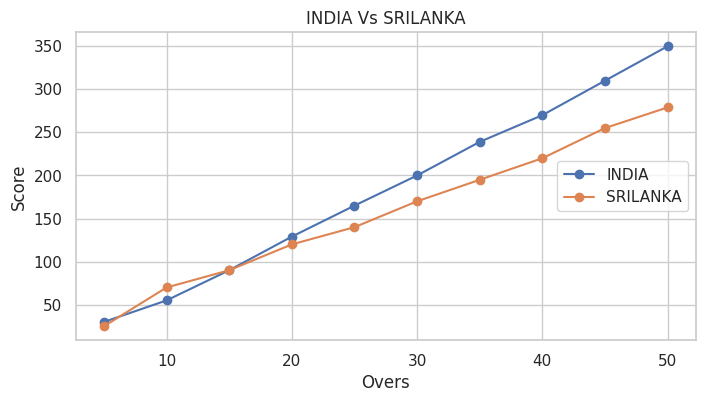

In [7]:
overs = list(range(5, 51, 5))
india_score = [30,55,90,129,165,200,239,270,310,350]
srilanka_score = [25,70,90,120,140,170,195,220,255,279]

plt.figure(figsize=(8,4))
plt.plot(overs, india_score, marker='o', label='INDIA')
plt.plot(overs, srilanka_score, marker='o', label='SRILANKA')
plt.title('INDIA Vs SRILANKA')
plt.xlabel('Overs'); plt.ylabel('Score')
plt.legend(loc='center right')
plt.show()

# Experiment 3(b): Data visualization using a bar chart

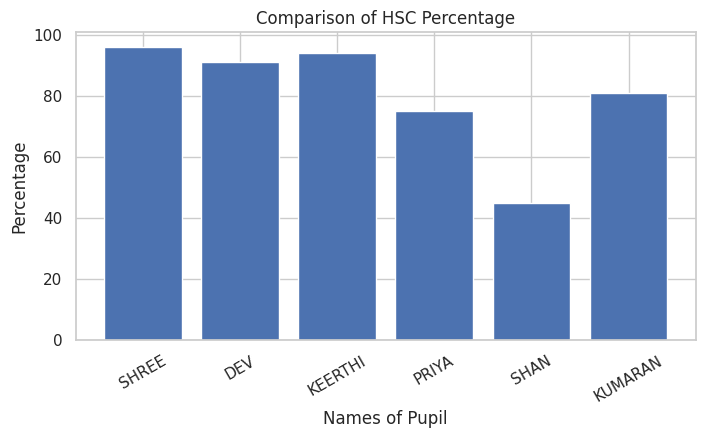

In [8]:
names = ['SHREE', 'DEV', 'KEERTHI', 'PRIYA', 'SHAN', 'KUMARAN']
percentage = [96, 91, 94, 75, 45, 81]
plt.figure(figsize=(8,4))
plt.bar(names, percentage)
plt.xlabel('Names of Pupil'); plt.ylabel('Percentage')
plt.title('Comparison of HSC Percentage')
plt.xticks(rotation=30)
plt.show()

# Experiment 3(c): Data visualization using a pie chart

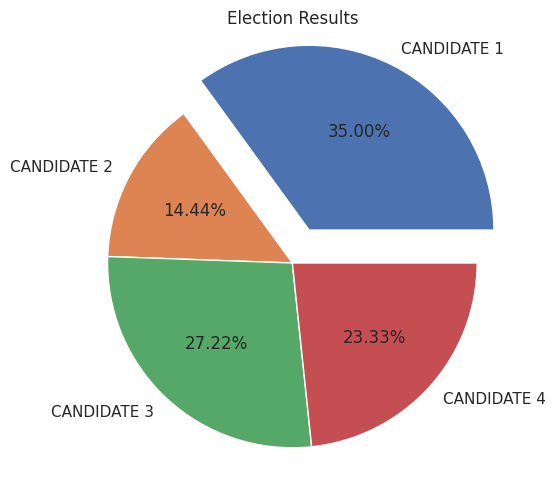

In [9]:
labels = ['CANDIDATE 1', 'CANDIDATE 2', 'CANDIDATE 3', 'CANDIDATE 4']
votes = [315, 130, 245, 210]
explode = (0.2, 0, 0, 0)
plt.figure(figsize=(6,6))
plt.pie(votes, labels=labels, explode=explode, autopct='%0.2f%%')
plt.title('Election Results')
plt.show()

# Experiment 4: Count frequency of occurrence of words in a body of text
**Colab adaptation:** Uses a fixed text sample, avoiding NLTK corpus downloads and internet dependency.

In [10]:
from collections import Counter
import re

sample_text = """Data science uses data to discover patterns. Data analysis helps
understand data. Python is widely used in data science and data visualization."""
words = re.findall(r'\b[a-zA-Z]+\b', sample_text.lower())
word_frequency = Counter(words)
print("Word-frequency pairs:")
print(list(word_frequency.items()))

Word-frequency pairs:
[('data', 6), ('science', 2), ('uses', 1), ('to', 1), ('discover', 1), ('patterns', 1), ('analysis', 1), ('helps', 1), ('understand', 1), ('python', 1), ('is', 1), ('widely', 1), ('used', 1), ('in', 1), ('and', 1), ('visualization', 1)]


# Experiment 5: Data collection and initial exploration
**Objective:** Load and explore a diabetes dataset. The manual names `diabetes.csv` but does not include the CSV, so this creates representative sample records with common diabetes-related columns.

First five rows:


,Pregnancies,Glucose,BloodPressure,BMI,Age,Outcome
0,1,85,66,26.6,31,0
1,0,89,70,28.1,22,0
2,3,120,80,32.0,35,1
3,2,110,72,29.5,28,0
4,5,145,85,35.2,45,1


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pregnancies    10 non-null     int64  
 1   Glucose        10 non-null     int64  
 2   BloodPressure  10 non-null     int64  
 3   BMI            10 non-null     float64
 4   Age            10 non-null     int64  
 5   Outcome        10 non-null     int64  
dtypes: float64(1), int64(5)
memory usage: 612.0 bytes
Summary statistics:


,Pregnancies,Glucose,BloodPressure,BMI,Age,Outcome
count,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000
mean,2.400000,114.900000,74.800000,30.090000,33.500000,0.400000
std,2.065591,24.496939,8.323995,3.676185,9.300538,0.516398
min,0.000000,85.000000,65.000000,24.800000,22.000000,0.000000
25%,1.000000,96.250000,68.500000,27.275000,26.500000,0.000000
50%,2.000000,112.500000,73.000000,29.850000,32.000000,0.000000
75%,3.750000,127.500000,79.500000,31.850000,39.500000,1.000000
max,6.000000,160.000000,90.000000,36.100000,50.000000,1.000000


Missing values:
Pregnancies      0
Glucose          0
BloodPressure    0
BMI              0
Age              0
Outcome          0
dtype: int64
Outcome counts:
Outcome
0    6
1    4
Name: count, dtype: int64


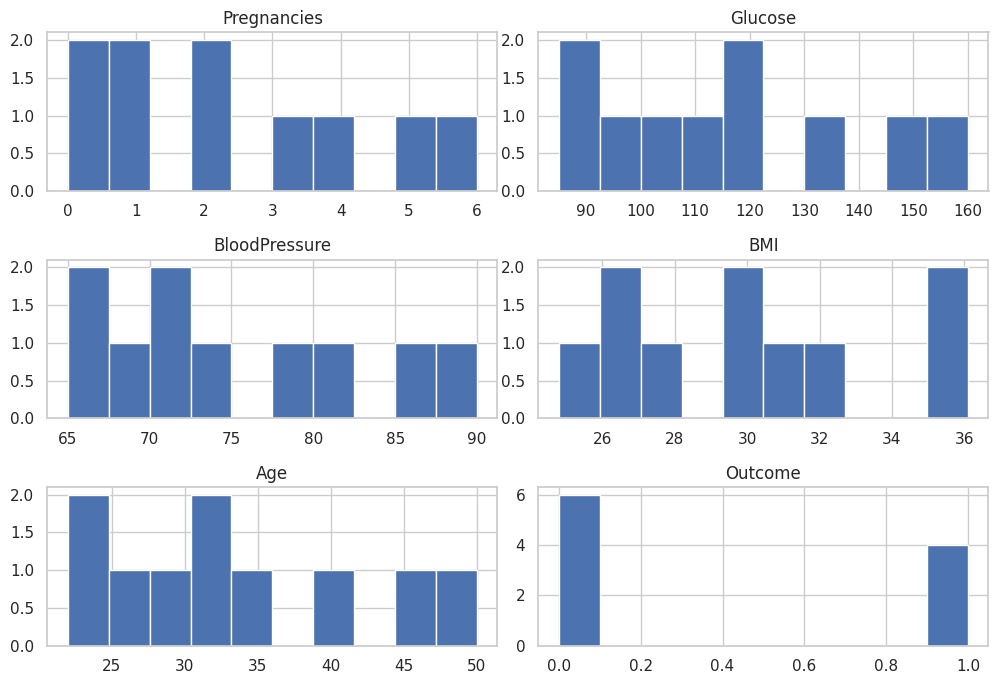

In [11]:
diabetes_df = pd.DataFrame({
    'Pregnancies':[1,0,3,2,5,1,4,0,2,6],
    'Glucose':[85,89,120,110,145,95,130,100,115,160],
    'BloodPressure':[66,70,80,72,85,68,78,65,74,90],
    'BMI':[26.6,28.1,32.0,29.5,35.2,24.8,31.4,27.0,30.2,36.1],
    'Age':[31,22,35,28,45,26,41,24,33,50],
    'Outcome':[0,0,1,0,1,0,1,0,0,1]
})
diabetes_df.to_csv('diabetes.csv', index=False)
diabetes_df = pd.read_csv('diabetes.csv')
print("First five rows:")
display(diabetes_df.head())
print("Dataset information:")
diabetes_df.info()
print("Summary statistics:")
display(diabetes_df.describe())
print("Missing values:")
print(diabetes_df.isnull().sum())
print("Outcome counts:")
print(diabetes_df['Outcome'].value_counts())
diabetes_df.hist(figsize=(10,7))
plt.tight_layout()
plt.show()

# Experiment 6: Time series analysis of website traffic
**Objective:** Identify trend, seasonality, moving average and anomalies.

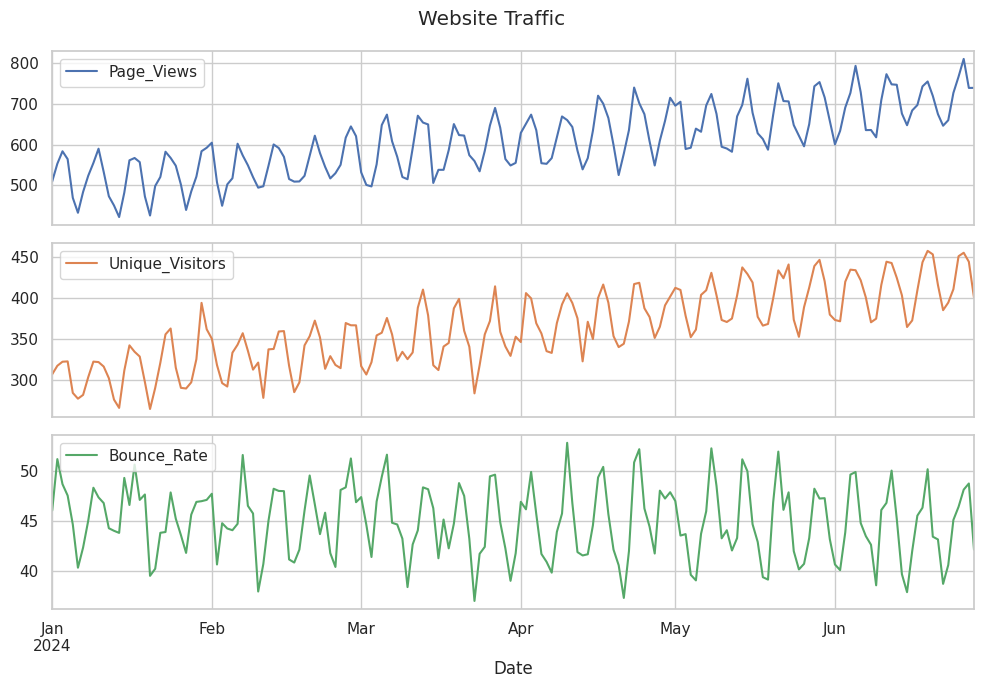

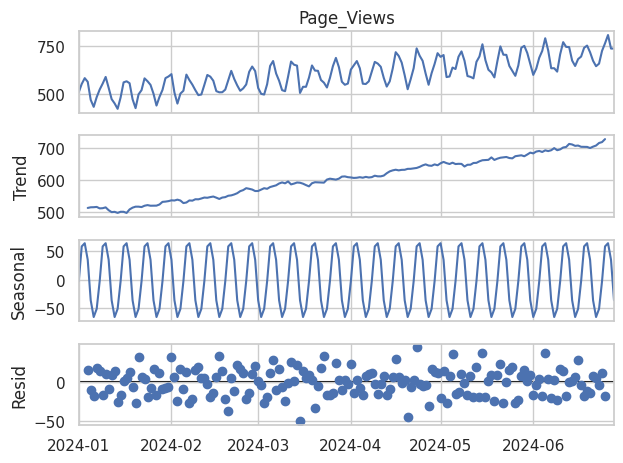

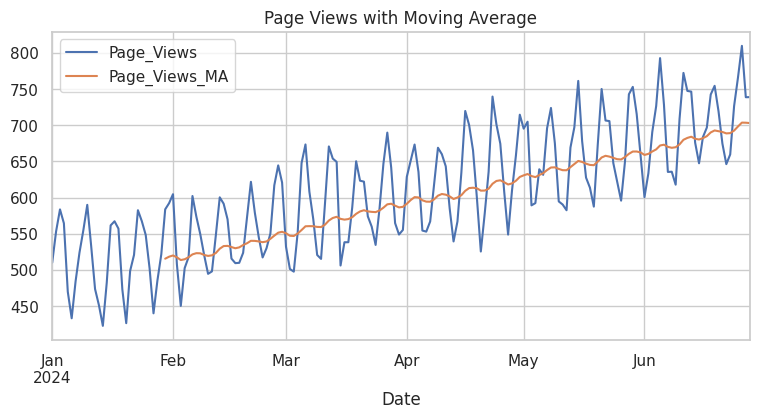

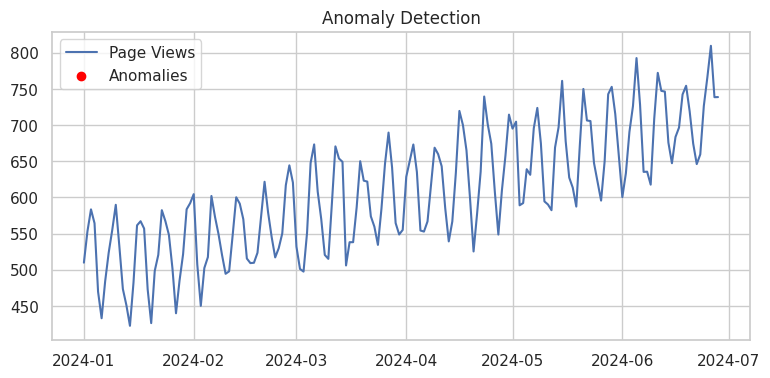

Detected anomalies:


,Page_Views,Page_Views_Z
Date,,


In [12]:
from statsmodels.tsa.seasonal import seasonal_decompose

dates = pd.date_range('2024-01-01', periods=180, freq='D')
day = np.arange(180)
website_data = pd.DataFrame({
    'Date': dates,
    'Page_Views': 500 + 1.2*day + 70*np.sin(2*np.pi*day/7) + np.random.normal(0, 20, 180),
    'Unique_Visitors': 300 + 0.7*day + 35*np.sin(2*np.pi*day/7) + np.random.normal(0, 12, 180),
    'Bounce_Rate': 45 + 4*np.sin(2*np.pi*day/7) + np.random.normal(0, 2, 180)
})
website_data.loc[50, 'Page_Views'] = np.nan
website_data['Page_Views'] = website_data['Page_Views'].interpolate()
website_data = website_data.set_index('Date')

website_data[['Page_Views','Unique_Visitors','Bounce_Rate']].plot(subplots=True, figsize=(10,7), title='Website Traffic')
plt.tight_layout(); plt.show()

decomposition = seasonal_decompose(website_data['Page_Views'], model='additive', period=7)
decomposition.plot()
plt.show()

website_data['Page_Views_MA'] = website_data['Page_Views'].rolling(window=30).mean()
website_data[['Page_Views','Page_Views_MA']].plot(figsize=(9,4), title='Page Views with Moving Average')
plt.show()

website_data['Page_Views_Z'] = (website_data['Page_Views'] - website_data['Page_Views'].mean()) / website_data['Page_Views'].std()
anomalies = website_data[website_data['Page_Views_Z'].abs() > 3]
plt.figure(figsize=(9,4))
plt.plot(website_data.index, website_data['Page_Views'], label='Page Views')
plt.scatter(anomalies.index, anomalies['Page_Views'], color='red', label='Anomalies')
plt.legend(); plt.title('Anomaly Detection'); plt.show()
print("Detected anomalies:")
display(anomalies[['Page_Views','Page_Views_Z']])

# Experiment 7: Random sampling and sampling distribution
**Objective:** Generate a population, repeatedly sample it, and plot the distribution of sample means.

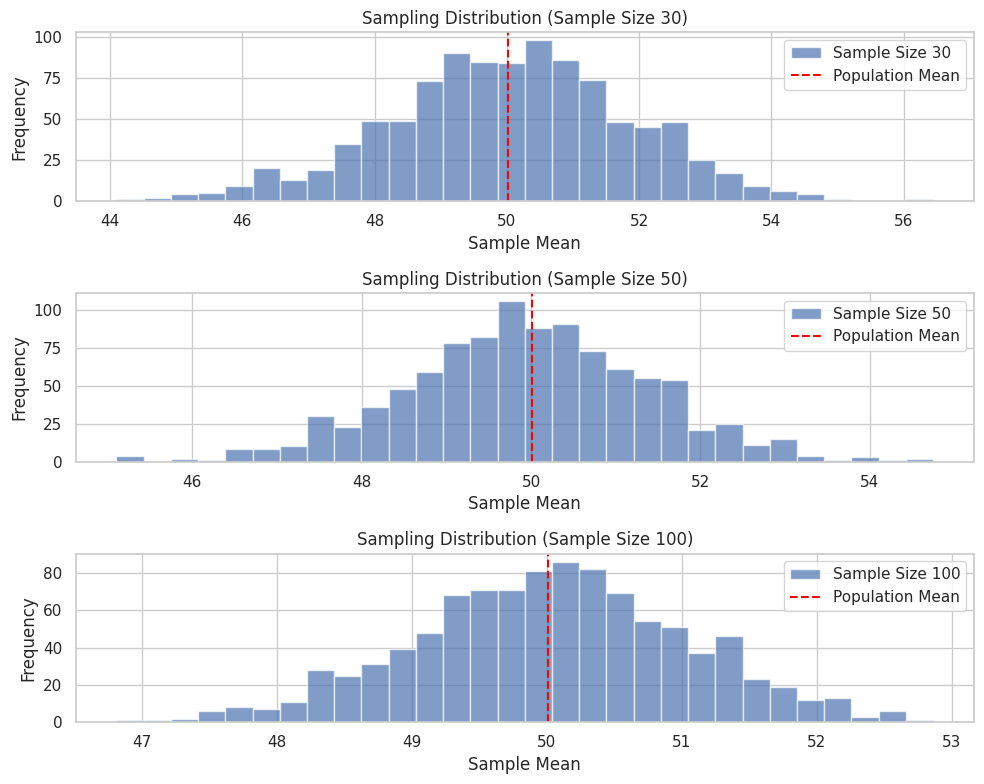

In [13]:
population_mean = 50
population_std = 10
population_size = 100000
population = np.random.normal(population_mean, population_std, population_size)

sample_sizes = [30, 50, 100]
num_samples = 1000
sample_means = {}

for size in sample_sizes:
    sample_means[size] = []
    for _ in range(num_samples):
        sample = np.random.choice(population, size=size, replace=False)
        sample_means[size].append(np.mean(sample))

plt.figure(figsize=(10,8))
for i, size in enumerate(sample_sizes):
    plt.subplot(len(sample_sizes), 1, i+1)
    plt.hist(sample_means[size], bins=30, alpha=0.7, label=f'Sample Size {size}')
    plt.axvline(np.mean(population), color='red', linestyle='dashed', linewidth=1.5, label='Population Mean')
    plt.title(f'Sampling Distribution (Sample Size {size})')
    plt.xlabel('Sample Mean'); plt.ylabel('Frequency'); plt.legend()
plt.tight_layout()
plt.show()

# Experiment 8: Conduct a Z-test using Python
**Objective:** Test whether the average bird weight differs from 150 grams using a two-tailed test at α = 0.05.

In [14]:
import scipy.stats as stats

sample_data = np.array([152,148,151,149,147,153,150,148,152,149,151,150,149,152,151,
                        148,150,152,149,150,148,153,151,150,149,152,148,151,150,153])
population_mean = 150
sample_mean = np.mean(sample_data)
sample_std = np.std(sample_data, ddof=1)
n = len(sample_data)

z_statistic = (sample_mean - population_mean) / (sample_std / np.sqrt(n))
p_value = 2 * (1 - stats.norm.cdf(abs(z_statistic)))

print(f"Sample Mean: {sample_mean:.2f}")
print(f"Z-Statistic: {z_statistic:.4f}")
print(f"P-Value: {p_value:.4f}")
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: average weight is significantly different from 150 grams.")
else:
    print("Fail to reject the null hypothesis: there is no significant difference from 150 grams.")

Sample Mean: 150.20
Z-Statistic: 0.6406
P-Value: 0.5218
Fail to reject the null hypothesis: there is no significant difference from 150 grams.


# Experiment 9: Matplotlib library use cases through visualization
**Objective:** Explore the Iris dataset and visualize its features.

   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm  target variety  \
0            5.1           3.5            1.4           0.2       0  setosa   
1            4.9           3.0            1.4           0.2       0  setosa   
2            4.7           3.2            1.3           0.2       0  setosa   
3            4.6           3.1            1.5           0.2       0  setosa   
4            5.0           3.6            1.4           0.2       0  setosa   

   Id  
0   1  
1   2  
2   3  
3   4  
4   5  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  150 non-null    float64
 1   SepalWidthCm   150 non-null    float64
 2   PetalLengthCm  150 non-null    float64
 3   PetalWidthCm   150 non-null    float64
 4   target         150 non-null    int64  
 5   variety        150 non-null    object 
 6   Id             1

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,target,Id
count,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000,75.500000
std,0.828066,0.435866,1.765298,0.762238,0.819232,43.445368
min,4.300000,2.000000,1.000000,0.100000,0.000000,1.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000,38.250000
50%,5.800000,3.000000,4.350000,1.300000,1.000000,75.500000
75%,6.400000,3.300000,5.100000,1.800000,2.000000,112.750000
max,7.900000,4.400000,6.900000,2.500000,2.000000,150.000000


variety
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


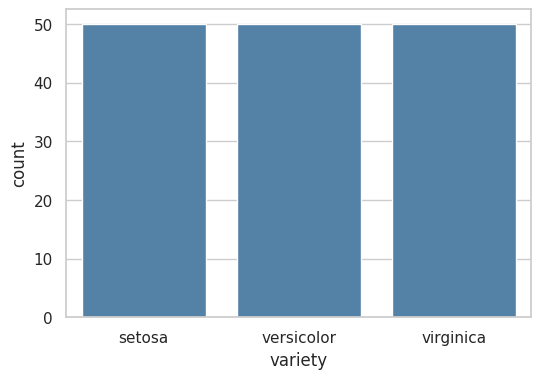

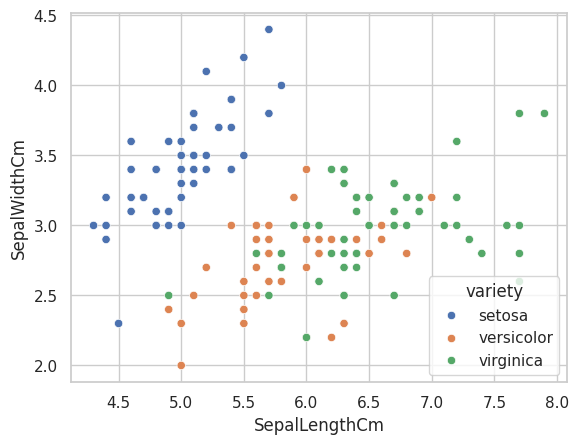

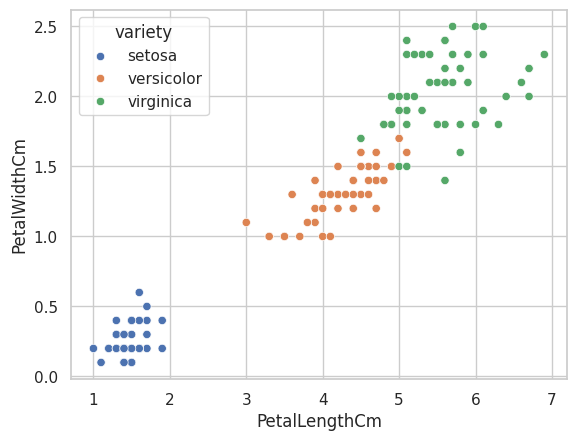

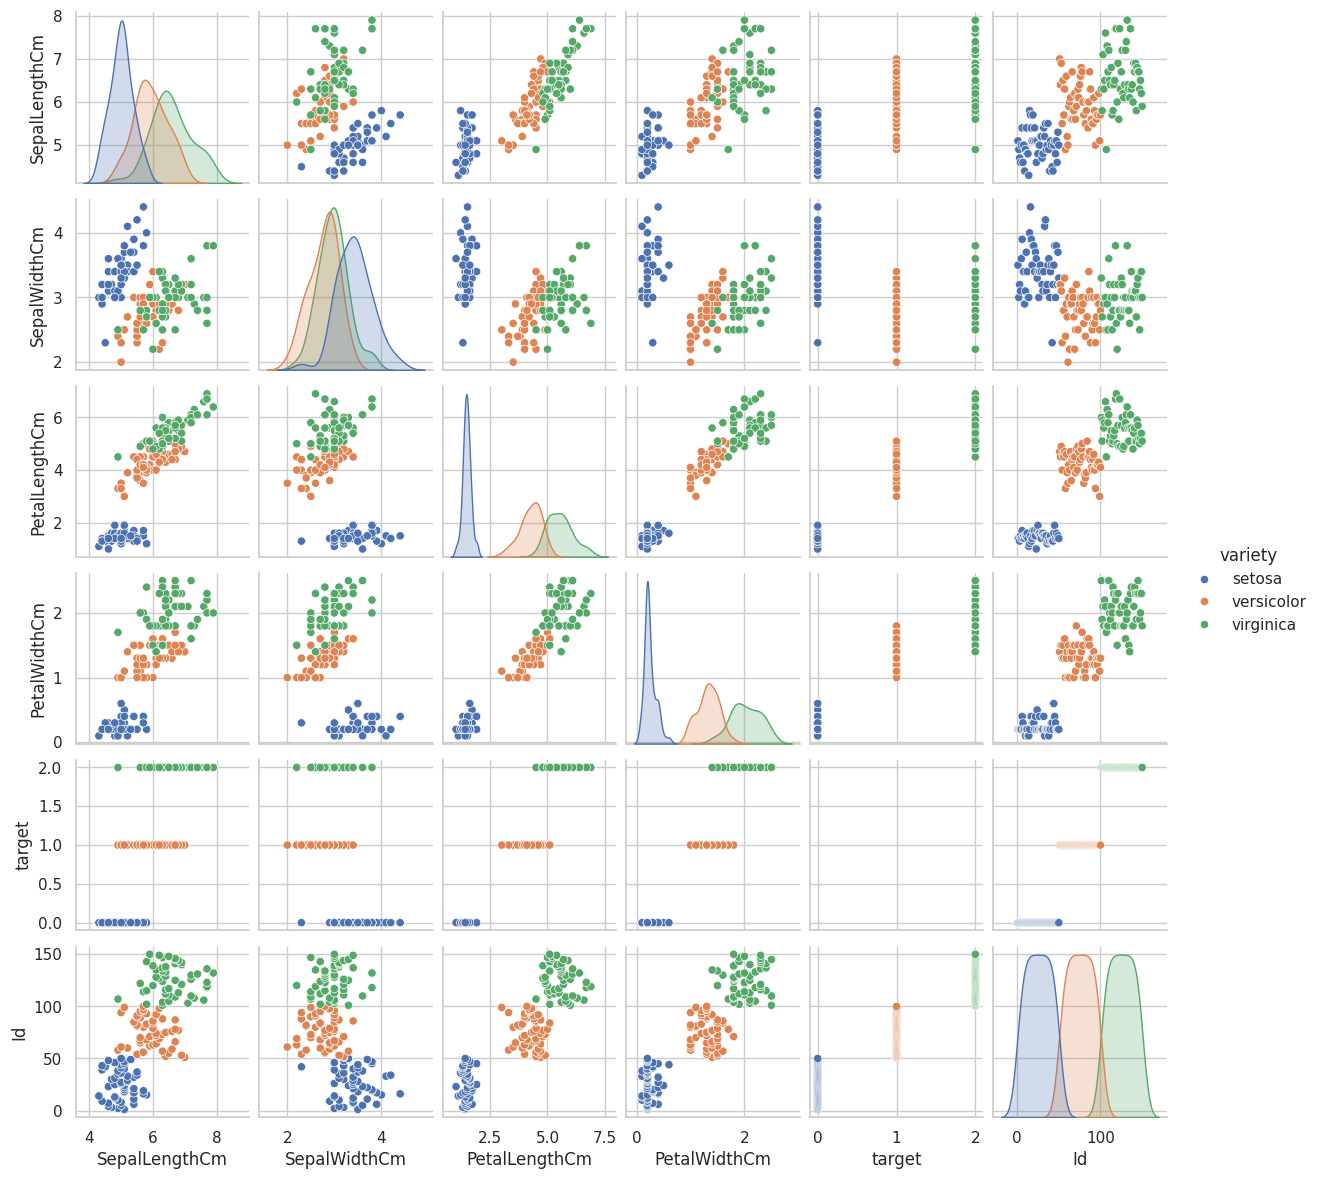

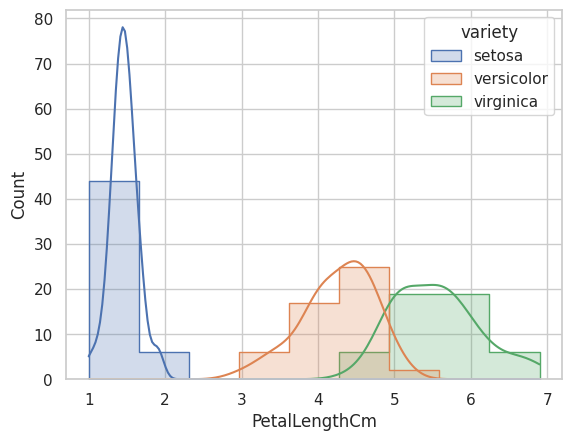

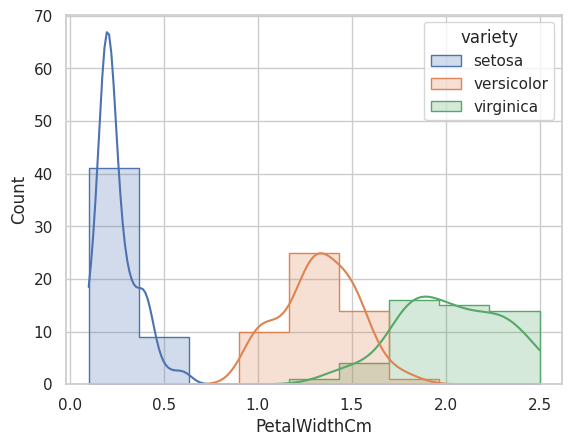

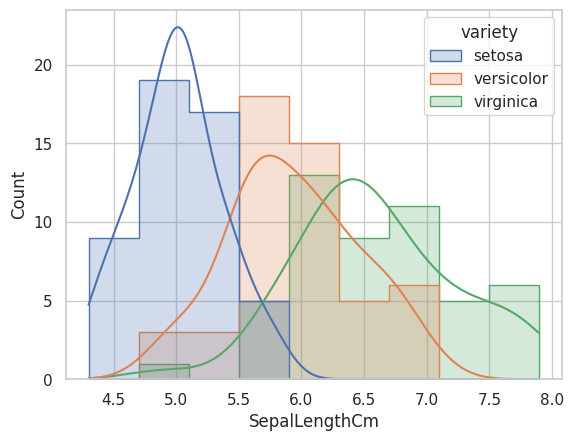

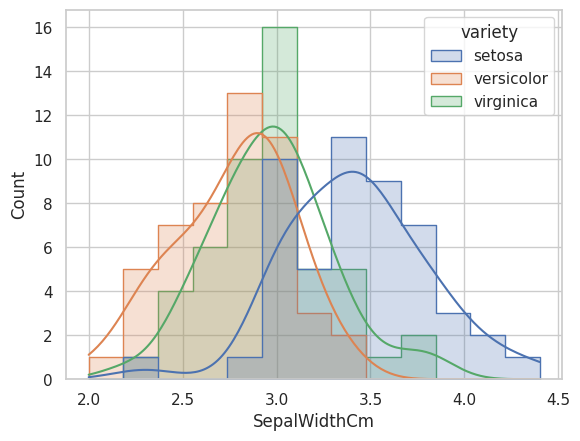

,setosa,versicolor,virginica,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,True,False,False,1,5.1,3.5,1.4,0.2
1,True,False,False,2,4.9,3.0,1.4,0.2
2,True,False,False,3,4.7,3.2,1.3,0.2
3,True,False,False,4,4.6,3.1,1.5,0.2
4,True,False,False,5,5.0,3.6,1.4,0.2


In [15]:
iris = load_iris(as_frame=True)
data = iris.frame
data['variety'] = data['target'].map(dict(enumerate(iris.target_names)))
data = data.rename(columns={
    'sepal length (cm)':'SepalLengthCm',
    'sepal width (cm)':'SepalWidthCm',
    'petal length (cm)':'PetalLengthCm',
    'petal width (cm)':'PetalWidthCm'
})
data['Id'] = np.arange(1, len(data)+1)
print(data.head())
data.info()
display(data.describe())
print(data['variety'].value_counts())

plt.figure(figsize=(6,4))
sns.countplot(data=data, x='variety', color='steelblue')
plt.show()

sns.scatterplot(data=data, x='SepalLengthCm', y='SepalWidthCm', hue='variety', palette='deep')
plt.show()
sns.scatterplot(data=data, x='PetalLengthCm', y='PetalWidthCm', hue='variety', palette='deep')
plt.show()
sns.pairplot(data, hue='variety', height=2, palette='deep')
plt.show()

for col in ['PetalLengthCm','PetalWidthCm','SepalLengthCm','SepalWidthCm']:
    sns.histplot(data=data, x=col, hue='variety', kde=True, element='step', palette='deep')
    plt.show()

dummies = pd.get_dummies(data['variety'])
final_dataset = pd.concat([dummies, data[['Id','SepalLengthCm','SepalWidthCm','PetalLengthCm','PetalWidthCm']]], axis=1)
display(final_dataset.head())

# Experiment 10: Understand NumPy array functions
**Objective:** Create arrays and use NumPy mathematical, reshape and slicing operations.

In [16]:
array = np.random.randint(1, 100, 9)
print("Original array:", array)
print("Square root:", np.sqrt(array))
print("Number of dimensions:", array.ndim)

new_array = array.reshape(3,3)
print("Reshaped array:\n", new_array)
print("Dimensions after reshape:", new_array.ndim)
print("Ravel:", new_array.ravel())

newm = new_array.reshape(3,3)
print("newm[2,1:3] =", newm[2,1:3])
print("newm[1:2,1:3] =", newm[1:2,1:3])
print("new_array[0:2,0:1] =\n", new_array[0:2,0:1])
print("new_array[0:3,0:1] =\n", new_array[0:3,0:1])
print("new_array[1:3] =\n", new_array[1:3])

Original array: [34 79 28 28 66 51 93 63 33]
Square root: [5.83095189 8.88819442 5.29150262 5.29150262 8.1240384  7.14142843
 9.64365076 7.93725393 5.74456265]
Number of dimensions: 1
Reshaped array:
 [[34 79 28]
 [28 66 51]
 [93 63 33]]
Dimensions after reshape: 2
Ravel: [34 79 28 28 66 51 93 63 33]
newm[2,1:3] = [63 33]
newm[1:2,1:3] = [[66 51]]
new_array[0:2,0:1] =
 [[34]
 [28]]
new_array[0:3,0:1] =
 [[34]
 [28]
 [93]]
new_array[1:3] =
 [[28 66 51]
 [93 63 33]]


# Experiment 11: Understand Pandas library use cases
**Objective:** Create DataFrames and explore CSV-style tabular data.

In [17]:
employee_list = [[1,'Smith',50000],[2,'Jones',60000]]
employee_df = pd.DataFrame(employee_list)
employee_df.columns = ['Empd','Name','Salary']
display(employee_df)
employee_df.info()

startup_df = pd.DataFrame({
    'R&D Spend':[165349.20,162597.70,153441.51,144372.41,142107.34],
    'Administration':[136897.80,151377.59,101145.55,118671.85,91391.77],
    'Marketing Spend':[471784.10,443898.53,407934.54,383199.62,366168.42],
    'State':['New York','California','Florida','New York','Florida'],
    'Profit':[192261.83,191792.06,191050.39,182901.99,166187.94]
})
startup_df.to_csv('50_Startups.csv', index=False)
df = pd.read_csv('50_Startups.csv')
print("Head:"); display(df.head())
print("Tail:"); display(df.tail())
df.info()
print("Mean profit:", df['Profit'].mean())
print("Columns:", df.columns)
print("Values as NumPy array:\n", df.values)

,Empd,Name,Salary
0,1,Smith,50000
1,2,Jones,60000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Empd    2 non-null      int64 
 1   Name    2 non-null      object
 2   Salary  2 non-null      int64 
dtypes: int64(2), object(1)
memory usage: 180.0+ bytes
Head:


,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


Tail:


,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        5 non-null      float64
 1   Administration   5 non-null      float64
 2   Marketing Spend  5 non-null      float64
 3   State            5 non-null      object 
 4   Profit           5 non-null      float64
dtypes: float64(4), object(1)
memory usage: 332.0+ bytes
Mean profit: 184838.842
Columns: Index(['R&D Spend', 'Administration', 'Marketing Spend', 'State', 'Profit'], dtype='object')
Values as NumPy array:
 [[165349.2 136897.8 471784.1 'New York' 192261.83]
 [162597.7 151377.59 443898.53 'California' 191792.06]
 [153441.51 101145.55 407934.54 'Florida' 191050.39]
 [144372.41 118671.85 383199.62 'New York' 182901.99]
 [142107.34 91391.77 366168.42 'Florida' 166187.94]]


# Experiment 12: Detect outliers in a dataset
**Objective:** Use quartiles and IQR to find and remove outliers.

Array: [ 8  4 40 91 44 12 43 55 74 61 57 95 21  9 26 54]
Mean: 43.375
25th percentile: 18.75
50th percentile: 43.5
75th percentile: 58.0
Lower range: -40.125 Upper range: 116.875
Outliers: []
After removing outliers: [ 8  4 40 91 44 12 43 55 74 61 57 95 21  9 26 54]


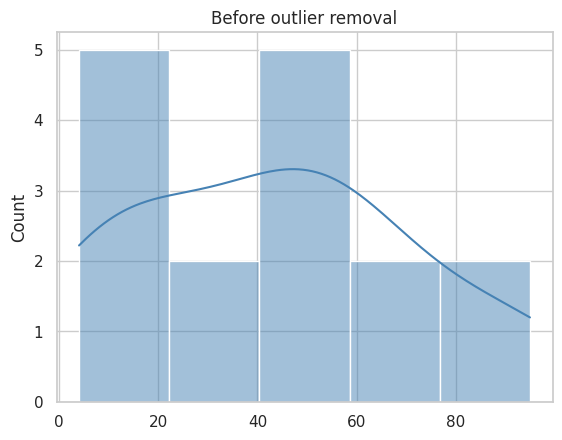

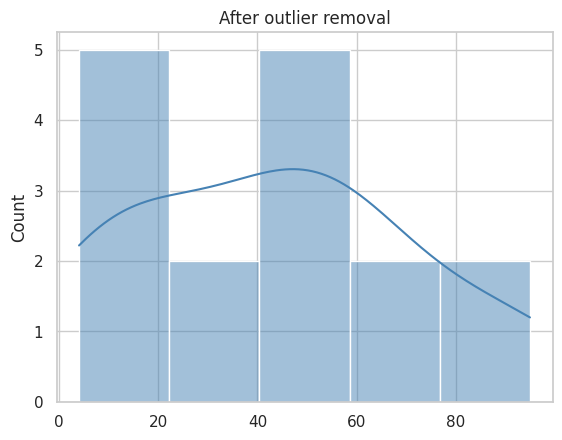

In [18]:
array = np.random.randint(1, 100, 16)
print("Array:", array)
print("Mean:", array.mean())
print("25th percentile:", np.percentile(array,25))
print("50th percentile:", np.percentile(array,50))
print("75th percentile:", np.percentile(array,75))

def outDetection(values):
    q1, q3 = np.percentile(values, [25,75])
    iqr = q3 - q1
    lower_range = q1 - 1.5 * iqr
    upper_range = q3 + 1.5 * iqr
    return lower_range, upper_range

lr, ur = outDetection(array)
print("Lower range:", lr, "Upper range:", ur)
outliers = array[(array < lr) | (array > ur)]
new_array = array[(array >= lr) & (array <= ur)]
print("Outliers:", outliers)
print("After removing outliers:", new_array)

sns.histplot(array, kde=True, color='steelblue')
plt.title('Before outlier removal')
plt.show()
sns.histplot(new_array, kde=True, color='steelblue')
plt.title('After outlier removal')
plt.show()

# Experiment 13: Handle missing values and inappropriate data
**Objective:** Detect invalid values, standardize categories and fill missing values.

In [19]:
df = pd.DataFrame({
    'CustomerID':[1,2,-3,4,5,6,7,8,9,10],
    'Age_Group':['20-25','25-30','30-35','35+','20-25','35+','35+','20-25','25-30','30-35'],
    'Rating(1-5)':[4,5,3,4,np.nan,3,4,-1,2,5],
    'Hotel':['Ibis','LemonTree','RedFox','Ibys','Ibis','Ibys','RedFox','LemonTree','Ibis','RedFox'],
    'FoodPreference':['veg','Non-Veg','Veg','Vegetarian','Non-Veg','Vegetarian','Non-Veg','Veg','non-Veg','Veg'],
    'Bill':[989,1909,1000,2999,3456,1909,1000,2999,3456,-100],
    'NoOfPax':[2,3,2,4,3,2,-1,-10,3,4],
    'EstimatedSalary':[45000,120000,54000,61000,np.nan,122220,21122,345673,-99999,87777]
})
display(df)
df.loc[df['CustomerID'] < 0, 'CustomerID'] = np.nan
df.loc[df['Bill'] < 0, 'Bill'] = np.nan
df.loc[df['EstimatedSalary'] < 0, 'EstimatedSalary'] = np.nan
df.loc[(df['NoOfPax'] < 1) | (df['NoOfPax'] > 20), 'NoOfPax'] = np.nan
df.loc[~df['Rating(1-5)'].between(1,5), 'Rating(1-5)'] = np.nan

df['Hotel'] = df['Hotel'].replace({'Ibys':'Ibis'})
df['FoodPreference'] = df['FoodPreference'].replace({
    'Vegetarian':'Veg', 'veg':'Veg', 'non-Veg':'Non-Veg'
})
df['EstimatedSalary'] = df['EstimatedSalary'].fillna(round(df['EstimatedSalary'].mean()))
df['NoOfPax'] = df['NoOfPax'].fillna(round(df['NoOfPax'].median()))
df['Rating(1-5)'] = df['Rating(1-5)'].fillna(round(df['Rating(1-5)'].median()))
df['Bill'] = df['Bill'].fillna(round(df['Bill'].mean()))
df['CustomerID'] = df['CustomerID'].fillna(df['CustomerID'].median())
display(df)
print("Missing values after cleaning:")
print(df.isnull().sum())

,CustomerID,Age_Group,Rating(1-5),Hotel,FoodPreference,Bill,NoOfPax,EstimatedSalary
0,1,20-25,4.0,Ibis,veg,989,2,45000.0
1,2,25-30,5.0,LemonTree,Non-Veg,1909,3,120000.0
2,-3,30-35,3.0,RedFox,Veg,1000,2,54000.0
3,4,35+,4.0,Ibys,Vegetarian,2999,4,61000.0
4,5,20-25,NaN,Ibis,Non-Veg,3456,3,NaN
5,6,35+,3.0,Ibys,Vegetarian,1909,2,122220.0
6,7,35+,4.0,RedFox,Non-Veg,1000,-1,21122.0
7,8,20-25,-1.0,LemonTree,Veg,2999,-10,345673.0
8,9,25-30,2.0,Ibis,non-Veg,3456,3,-99999.0
9,10,30-35,5.0,RedFox,Veg,-100,4,87777.0


,CustomerID,Age_Group,Rating(1-5),Hotel,FoodPreference,Bill,NoOfPax,EstimatedSalary
0,1.0,20-25,4.0,Ibis,Veg,989.0,2.0,45000.0
1,2.0,25-30,5.0,LemonTree,Non-Veg,1909.0,3.0,120000.0
2,6.0,30-35,3.0,RedFox,Veg,1000.0,2.0,54000.0
3,4.0,35+,4.0,Ibis,Veg,2999.0,4.0,61000.0
4,5.0,20-25,4.0,Ibis,Non-Veg,3456.0,3.0,107099.0
5,6.0,35+,3.0,Ibis,Veg,1909.0,2.0,122220.0
6,7.0,35+,4.0,RedFox,Non-Veg,1000.0,3.0,21122.0
7,8.0,20-25,4.0,LemonTree,Veg,2999.0,3.0,345673.0
8,9.0,25-30,2.0,Ibis,Non-Veg,3456.0,3.0,107099.0
9,10.0,30-35,5.0,RedFox,Veg,2191.0,4.0,87777.0


Missing values after cleaning:
CustomerID         0
Age_Group          0
Rating(1-5)        0
Hotel              0
FoodPreference     0
Bill               0
NoOfPax            0
EstimatedSalary    0
dtype: int64


# Experiment 14: Understand feature scaling
**Objective:** Apply standardization and normalization to numerical features.

In [20]:
scale_data = pd.DataFrame({
    'Age':[25,30,35,40,45],
    'Salary':[25000,40000,50000,65000,80000]
})
print("Original data:")
display(scale_data)

standard_scaler = StandardScaler()
standardized = standard_scaler.fit_transform(scale_data)
print("Standardized data:")
display(pd.DataFrame(standardized, columns=scale_data.columns))

minmax_scaler = MinMaxScaler()
normalized = minmax_scaler.fit_transform(scale_data)
print("Normalized data:")
display(pd.DataFrame(normalized, columns=scale_data.columns))

Original data:


,Age,Salary
0,25,25000
1,30,40000
2,35,50000
3,40,65000
4,45,80000


Standardized data:


,Age,Salary
0,-1.414214,-1.411313
1,-0.707107,-0.627250
2,0.000000,-0.104542
3,0.707107,0.679521
4,1.414214,1.463583


Normalized data:


,Age,Salary
0,0.00,0.000000
1,0.25,0.272727
2,0.50,0.454545
3,0.75,0.727273
4,1.00,1.000000


# Experiment 15: Understand data preprocessing
**Objective:** Handle missing values, encode categorical variables and prepare data.

In [21]:
df = pd.DataFrame({
    'Country':['France','Spain','Germany','Spain','Germany','France','Spain','France','France','France'],
    'Age':[44,27,30,38,40,35,38,48,50,37],
    'Salary':[72000,48000,54000,61000,63778,58000,52000,79000,83000,67000],
    'Purchased':['No','Yes','No','No','Yes','Yes','No','Yes','No','Yes']
})
df.loc[2,'Age'] = np.nan
df.loc[4,'Salary'] = np.nan
df.loc[6,'Country'] = np.nan
display(df)

df['Country'] = df['Country'].fillna(df['Country'].mode()[0])
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Salary'] = df['Salary'].fillna(round(df['Salary'].mean()))
print("After filling missing values:")
display(df)

country_dummies = pd.get_dummies(df['Country'])
updated_dataset = pd.concat([country_dummies, df[['Age','Salary','Purchased']]], axis=1)
updated_dataset['Purchased'] = updated_dataset['Purchased'].replace({'No':0,'Yes':1})
print("Encoded dataset:")
display(updated_dataset)
updated_dataset.info()

,Country,Age,Salary,Purchased
0,France,44.0,72000.0,No
1,Spain,27.0,48000.0,Yes
2,Germany,NaN,54000.0,No
3,Spain,38.0,61000.0,No
4,Germany,40.0,NaN,Yes
5,France,35.0,58000.0,Yes
6,NaN,38.0,52000.0,No
7,France,48.0,79000.0,Yes
8,France,50.0,83000.0,No
9,France,37.0,67000.0,Yes


After filling missing values:


,Country,Age,Salary,Purchased
0,France,44.0,72000.0,No
1,Spain,27.0,48000.0,Yes
2,Germany,38.0,54000.0,No
3,Spain,38.0,61000.0,No
4,Germany,40.0,63778.0,Yes
5,France,35.0,58000.0,Yes
6,France,38.0,52000.0,No
7,France,48.0,79000.0,Yes
8,France,50.0,83000.0,No
9,France,37.0,67000.0,Yes


Encoded dataset:


/tmp/ipykernel_2432/2753141118.py:20: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  updated_dataset['Purchased'] = updated_dataset['Purchased'].replace({'No':0,'Yes':1})


,France,Germany,Spain,Age,Salary,Purchased
0,True,False,False,44.0,72000.0,0
1,False,False,True,27.0,48000.0,1
2,False,True,False,38.0,54000.0,0
3,False,False,True,38.0,61000.0,0
4,False,True,False,40.0,63778.0,1
5,True,False,False,35.0,58000.0,1
6,True,False,False,38.0,52000.0,0
7,True,False,False,48.0,79000.0,1
8,True,False,False,50.0,83000.0,0
9,True,False,False,37.0,67000.0,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   France     10 non-null     bool   
 1   Germany    10 non-null     bool   
 2   Spain      10 non-null     bool   
 3   Age        10 non-null     float64
 4   Salary     10 non-null     float64
 5   Purchased  10 non-null     int64  
dtypes: bool(3), float64(2), int64(1)
memory usage: 402.0 bytes


# Experiment 16: EDA – Quantitative and Qualitative analysis
**Objective:** Explore numerical and categorical features using plots and summary statistics. The manual uses the Seaborn `tips` dataset; this notebook creates a local sample with the same columns to avoid downloading a dataset.

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


Quantitative summary:


,total_bill,tip,size
count,12.000000,12.000000,12.000000
mean,21.025833,2.932500,2.833333
std,6.843499,1.185105,1.029857
min,10.340000,1.010000,2.000000
25%,16.542500,1.950000,2.000000
50%,20.405000,3.005000,2.500000
75%,25.317500,3.682500,3.250000
max,32.100000,5.000000,5.000000


Qualitative summary:


,sex,smoker,day,time
count,12,12,12,12
unique,2,2,4,2
top,Female,No,Sun,Dinner
freq,6,9,6,9


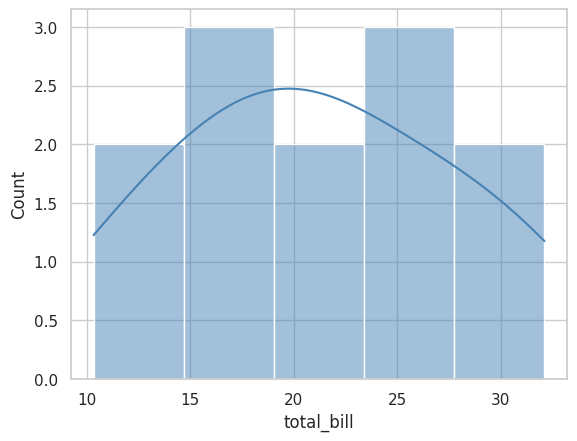

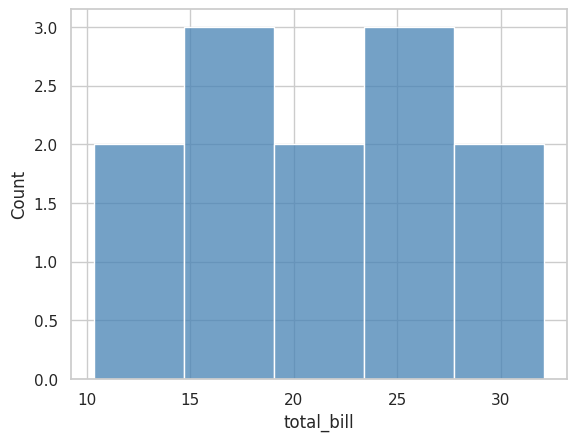

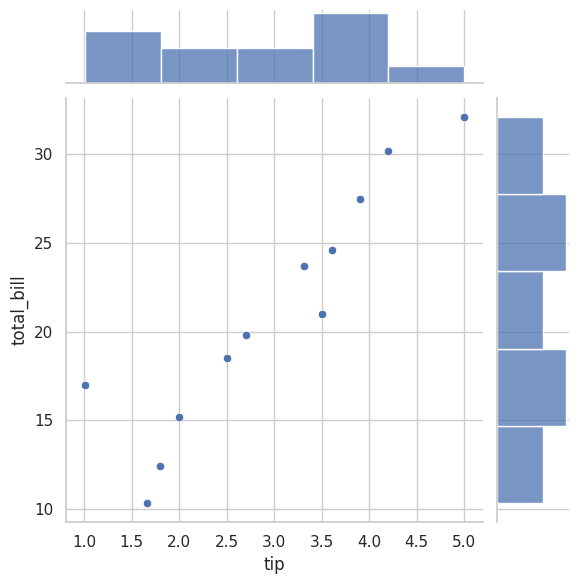

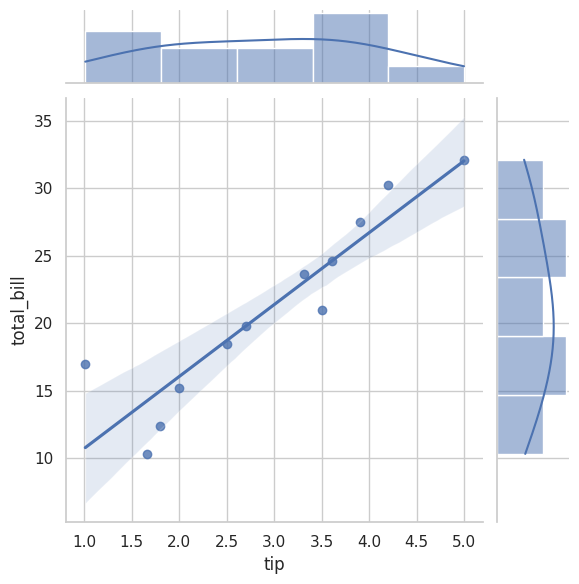

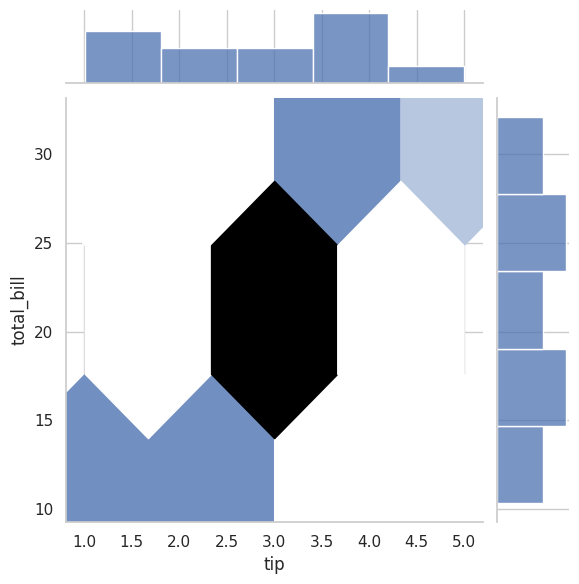

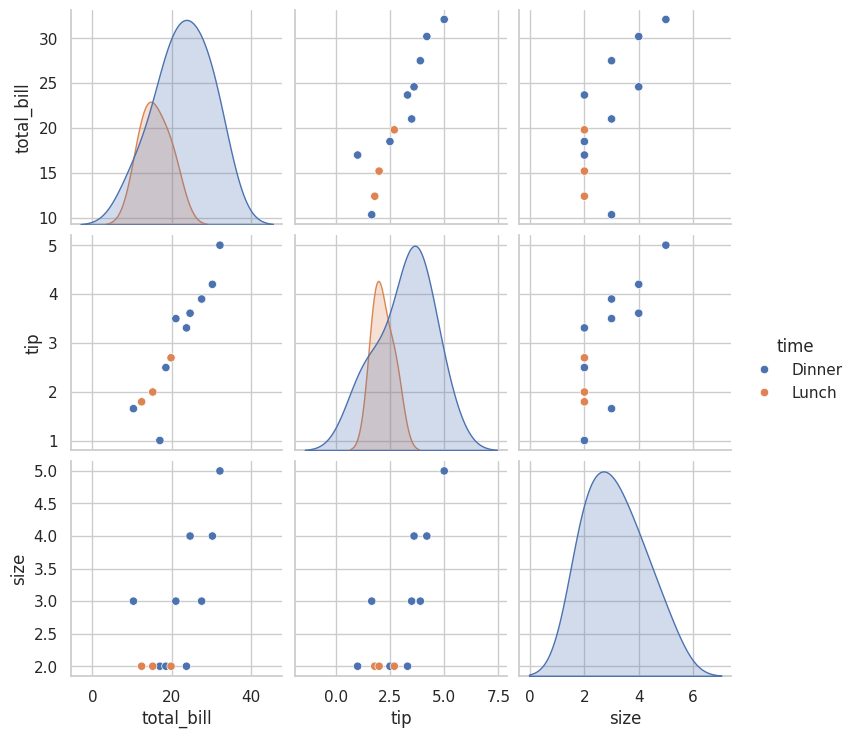

time
Dinner    9
Lunch     3
Name: count, dtype: int64


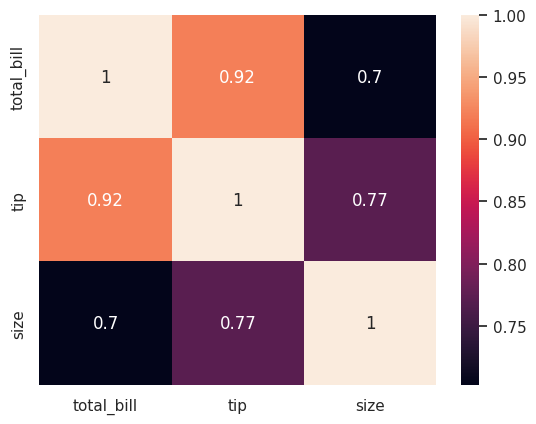

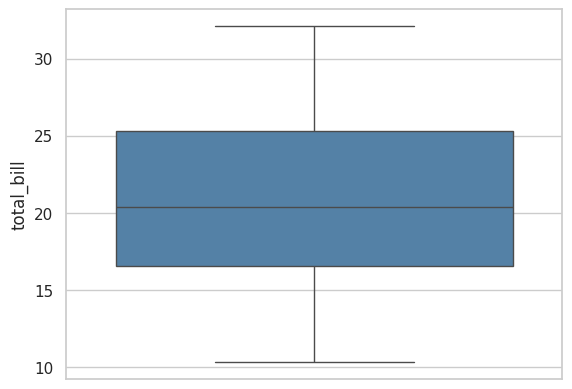

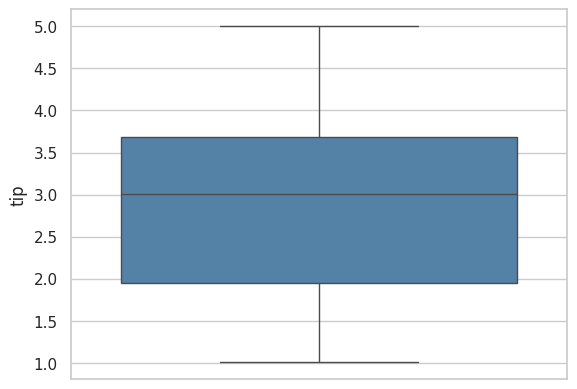

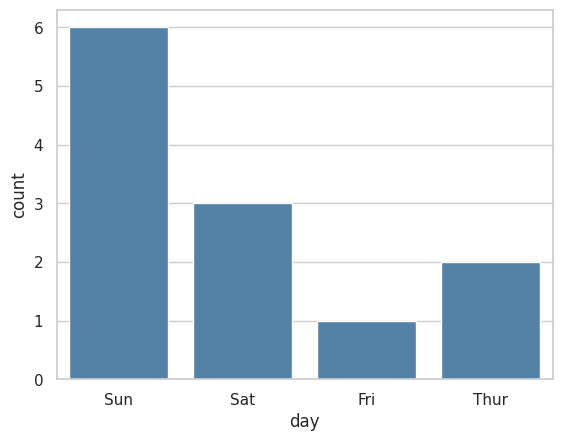

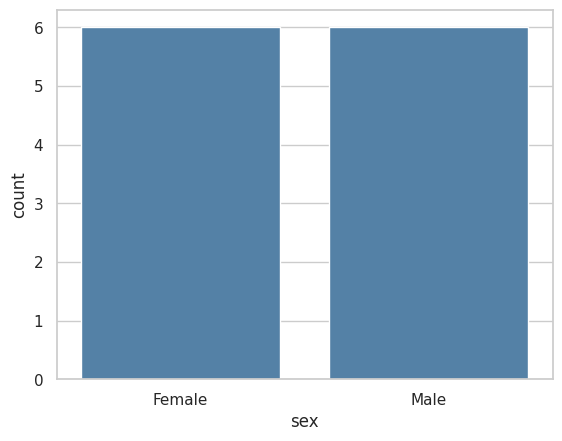

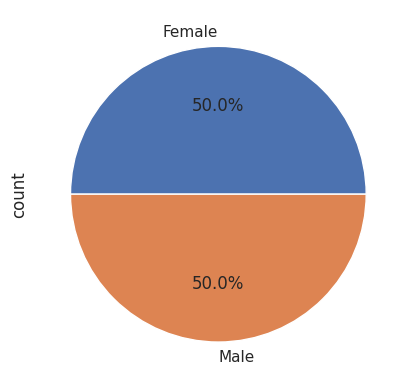

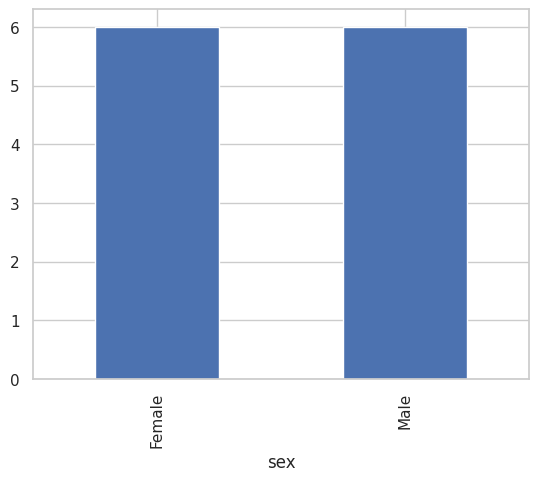

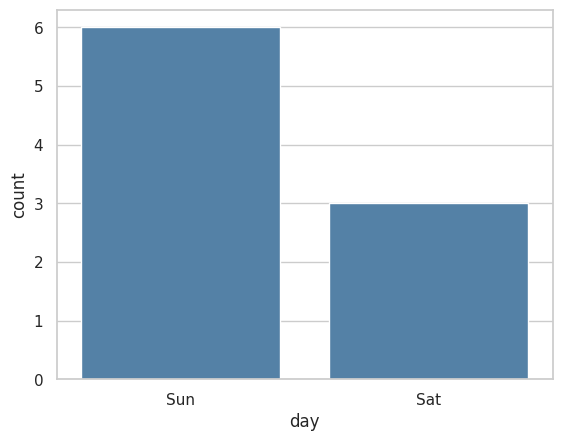

In [22]:
tips = pd.DataFrame({
    'total_bill':[16.99,10.34,21.01,23.68,24.59,18.5,30.2,12.4,27.5,19.8,15.2,32.1],
    'tip':[1.01,1.66,3.50,3.31,3.61,2.5,4.2,1.8,3.9,2.7,2.0,5.0],
    'sex':['Female','Male','Male','Male','Female','Female','Male','Female','Male','Female','Male','Female'],
    'smoker':['No','No','No','No','No','Yes','No','Yes','No','Yes','No','No'],
    'day':['Sun','Sun','Sun','Sun','Sun','Sat','Sat','Fri','Sat','Thur','Thur','Sun'],
    'time':['Dinner','Dinner','Dinner','Dinner','Dinner','Dinner','Dinner','Lunch','Dinner','Lunch','Lunch','Dinner'],
    'size':[2,3,3,2,4,2,4,2,3,2,2,5]
})
display(tips.head())
print("Quantitative summary:")
display(tips.describe())
print("Qualitative summary:")
display(tips.describe(include='object'))
sns.histplot(data=tips, x='total_bill', kde=True, color='steelblue'); plt.show()
sns.histplot(data=tips, x='total_bill', color='steelblue'); plt.show()
sns.jointplot(data=tips, x='tip', y='total_bill'); plt.show()
sns.jointplot(data=tips, x='tip', y='total_bill', kind='reg'); plt.show()
sns.jointplot(data=tips, x='tip', y='total_bill', kind='hex'); plt.show()
sns.pairplot(tips, hue='time', palette='deep'); plt.show()
print(tips['time'].value_counts())
sns.heatmap(tips.corr(numeric_only=True), annot=True); plt.show()
sns.boxplot(data=tips, y='total_bill', color='steelblue'); plt.show()
sns.boxplot(data=tips, y='tip', color='steelblue'); plt.show()
sns.countplot(data=tips, x='day', color='steelblue'); plt.show()
sns.countplot(data=tips, x='sex', color='steelblue'); plt.show()
tips['sex'].value_counts().plot(kind='pie', autopct='%1.1f%%'); plt.show()
tips['sex'].value_counts().plot(kind='bar'); plt.show()
sns.countplot(data=tips[tips.time=='Dinner'], x='day', color='steelblue'); plt.show()

# Experiment 17: Linear Regression
**Objective:** Train a linear regression model to estimate salary from years of experience.

,YearsExperience,Salary
0,1.1,39343
1,1.3,46205
2,1.5,37731
3,2.0,43525
4,2.2,39891


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 612.0 bytes


,YearsExperience,Salary
count,30.000000,30.000000
mean,5.486667,77786.900000
std,2.871349,27457.242835
min,1.100000,37731.000000
25%,3.050000,56006.000000
50%,5.200000,74650.500000
75%,7.800000,100544.750000
max,10.500000,122391.000000


Training score: 0.9598542320798474
Testing score: 0.9915888120541615
Coefficient: [[9353.80359294]]
Intercept: [26400.90769389]


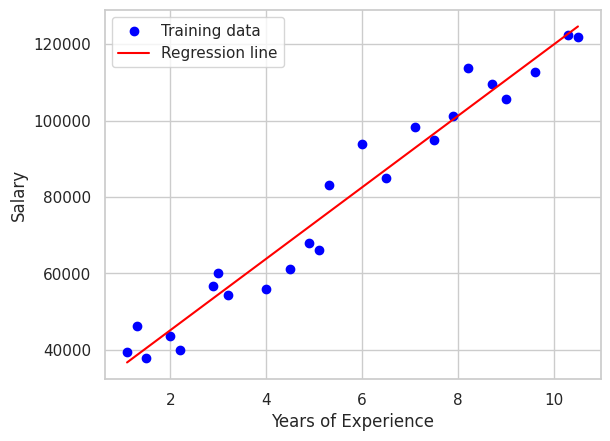

Enter Years of Experience: 4.5
Estimated Salary for 4.5 years of experience is 68493.02


In [23]:
salary_df = pd.DataFrame({
    'YearsExperience':[1.1,1.3,1.5,2.0,2.2,2.9,3.0,3.2,3.7,3.9,4.0,4.5,4.9,5.1,5.3,
                       5.9,6.0,6.8,7.1,7.9,8.2,8.7,9.0,9.5,9.6,10.3,10.5,2.5,6.5,7.5],
    'Salary':[39343,46205,37731,43525,39891,56642,60150,54445,57189,63218,55794,61111,
              67938,66029,83088,81363,93940,91738,98273,101302,113812,109431,105582,
              116969,112635,122391,121872,52000,85000,95000]
})
display(salary_df.head())
salary_df.info()
salary_df.dropna(inplace=True)
display(salary_df.describe())

features = salary_df[['YearsExperience']].values
label = salary_df[['Salary']].values
x_train, x_test, y_train, y_test = train_test_split(features, label, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(x_train, y_train)
print("Training score:", model.score(x_train, y_train))
print("Testing score:", model.score(x_test, y_test))
print("Coefficient:", model.coef_)
print("Intercept:", model.intercept_)

predictions = model.predict(x_test)
plt.scatter(x_train, y_train, color='blue', label='Training data')
sorted_idx = np.argsort(x_train[:, 0])
plt.plot(x_train[sorted_idx, 0], model.predict(x_train[sorted_idx]).ravel(), color='red', label='Regression line')
plt.xlabel('Years of Experience'); plt.ylabel('Salary'); plt.legend(); plt.show()

yr_of_exp = float(input("Enter Years of Experience: "))
salary = model.predict(np.array([[yr_of_exp]]))
print(f"Estimated Salary for {yr_of_exp} years of experience is {salary[0][0]:.2f}")

# Experiment 18: K-Nearest Neighbors (KNN)
**Objective:** Classify Iris flowers using the KNN algorithm.

In [24]:
iris_df = load_iris(as_frame=True).frame
iris_df['variety'] = iris_df['target'].map({0:'Setosa',1:'Versicolor',2:'Virginica'})
iris_df = iris_df.drop(columns=['target'])
iris_df.columns = ['sepal.length','sepal.width','petal.length','petal.width','variety']
iris_df.info()
print(iris_df['variety'].value_counts())
display(iris_df.head())

features = iris_df.iloc[:,:-1].values
label = iris_df['variety'].values
xtrain, xtest, ytrain, ytest = train_test_split(features, label, test_size=0.2, random_state=42, stratify=label)

scaler = StandardScaler()
xtrain = scaler.fit_transform(xtrain)
xtest = scaler.transform(xtest)

model_KNN = KNeighborsClassifier(n_neighbors=5)
model_KNN.fit(xtrain, ytrain)
print("Training accuracy:", model_KNN.score(xtrain, ytrain))
print("Testing accuracy:", model_KNN.score(xtest, ytest))
y_pred = model_KNN.predict(xtest)
print("Confusion matrix:\n", confusion_matrix(ytest, y_pred))
print(classification_report(ytest, y_pred))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal.length  150 non-null    float64
 1   sepal.width   150 non-null    float64
 2   petal.length  150 non-null    float64
 3   petal.width   150 non-null    float64
 4   variety       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
variety
Setosa        50
Versicolor    50
Virginica     50
Name: count, dtype: int64


,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


Training accuracy: 0.975
Testing accuracy: 0.9333333333333333
Confusion matrix:
 [[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       0.83      1.00      0.91        10
   Virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



# Experiment 19: Logistic Regression
**Objective:** Predict whether a person purchases a product based on age and estimated salary.

In [25]:
n = 400
age = np.random.randint(18, 61, n)
salary = np.random.randint(15000, 150001, n)
purchase_probability = 1 / (1 + np.exp(-(-5 + 0.10*age + 0.000035*salary)))
purchased = np.random.binomial(1, purchase_probability)
social_df = pd.DataFrame({
    'User ID': np.arange(15600000, 15600000+n),
    'Gender': np.random.choice(['Male','Female'], n),
    'Age': age,
    'EstimatedSalary': salary,
    'Purchased': purchased
})
display(social_df.head())

features = social_df[['Age','EstimatedSalary']].values
label = social_df['Purchased'].values
x_train, x_test, y_train, y_test = train_test_split(features, label, test_size=0.2, random_state=42, stratify=label)

scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

log_model = LogisticRegression()
log_model.fit(x_train, y_train)
print("Training accuracy:", log_model.score(x_train, y_train))
print("Testing accuracy:", log_model.score(x_test, y_test))
y_pred = log_model.predict(x_test)
print(classification_report(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

new_person = scaler.transform([[35, 70000]])
print("Prediction for age 35 and salary 70000:", log_model.predict(new_person)[0])

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15600000,Male,49,56223,0
1,15600001,Male,43,68293,0
2,15600002,Male,52,149940,1
3,15600003,Female,46,71757,1
4,15600004,Female,28,95539,1


Training accuracy: 0.84375
Testing accuracy: 0.8125
              precision    recall  f1-score   support

           0       0.60      0.50      0.55        18
           1       0.86      0.90      0.88        62

    accuracy                           0.81        80
   macro avg       0.73      0.70      0.71        80
weighted avg       0.80      0.81      0.81        80

Confusion matrix:
 [[ 9  9]
 [ 6 56]]
Prediction for age 35 and salary 70000: 1


# Experiment 20: K-Means clustering
**Objective:** Group mall customers using annual income and spending score.

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Female,23,98,95
1,2,Male,61,32,67
2,3,Female,26,133,15
3,4,Female,57,99,34
4,5,Male,36,81,3


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


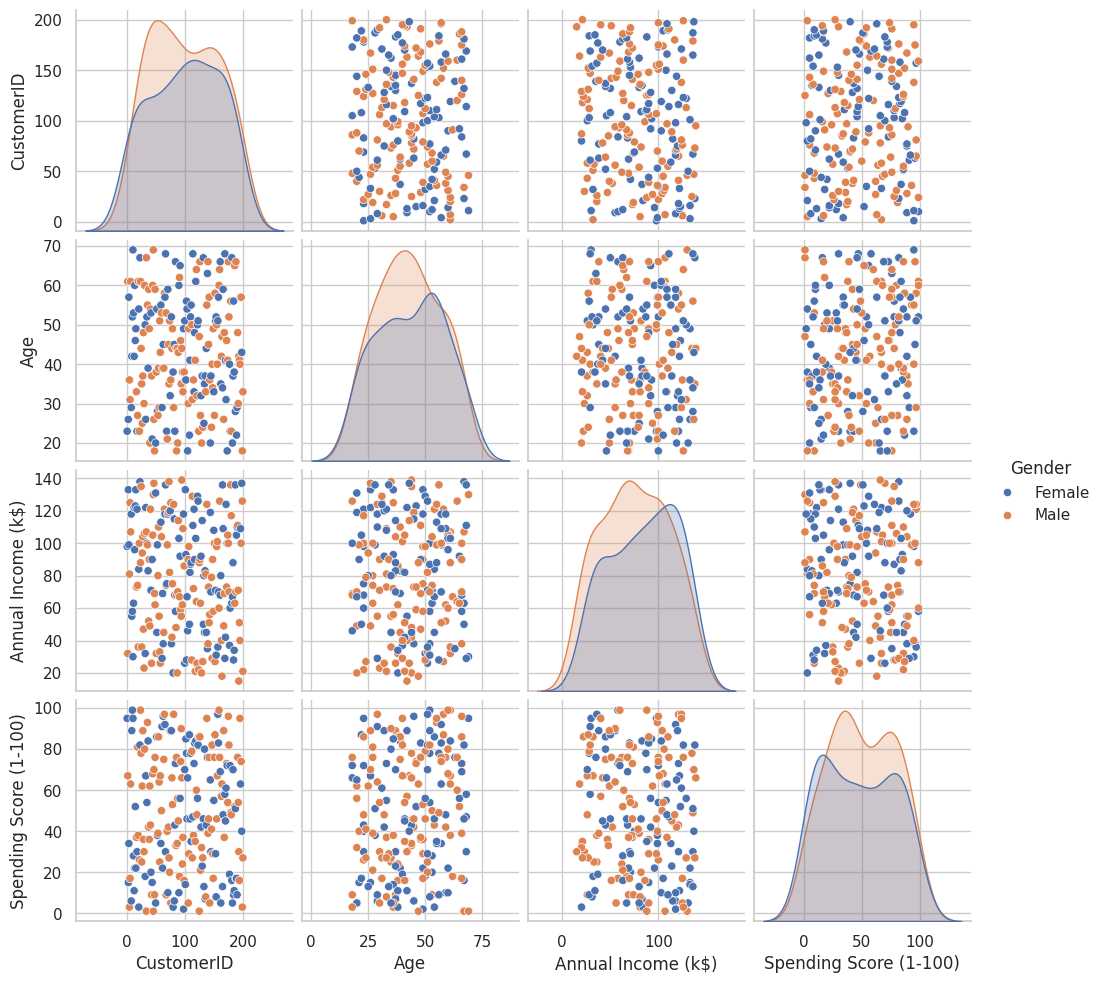

,Annual Income (k$),Spending Score (1-100),label
0,98,95,1
1,32,67,2
2,133,15,4
3,99,34,3
4,81,3,3


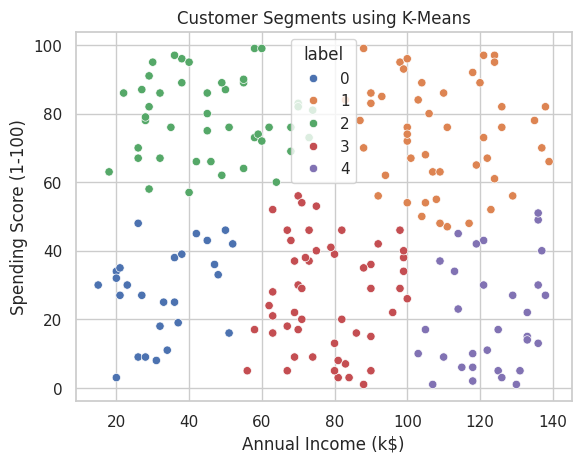

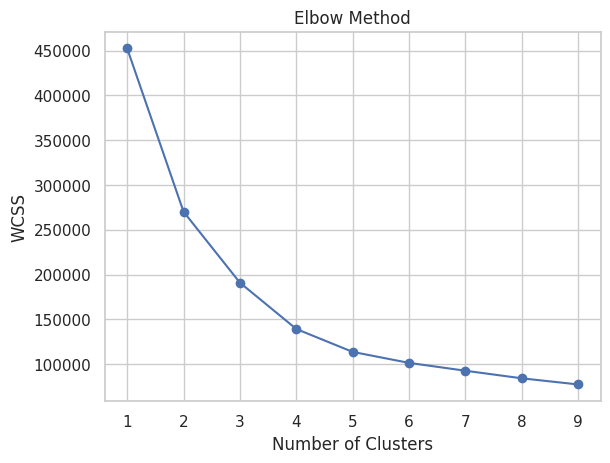

In [26]:
n = 200
mall_df = pd.DataFrame({
    'CustomerID': np.arange(1, n+1),
    'Gender': np.random.choice(['Male','Female'], n),
    'Age': np.random.randint(18, 70, n),
    'Annual Income (k$)': np.random.randint(15, 140, n),
    'Spending Score (1-100)': np.random.randint(1, 100, n)
})
display(mall_df.head())
mall_df.info()
sns.pairplot(mall_df, hue='Gender', palette='deep')
plt.show()

features = mall_df[['Annual Income (k$)','Spending Score (1-100)']].values
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
kmeans.fit(features)
Final = mall_df[['Annual Income (k$)','Spending Score (1-100)']].copy()
Final['label'] = kmeans.predict(features)
display(Final.head())

sns.scatterplot(data=Final, x='Annual Income (k$)', y='Spending Score (1-100)', hue='label', palette='deep')
plt.title('Customer Segments using K-Means')
plt.show()

features_elbow = mall_df[['Age','Annual Income (k$)','Spending Score (1-100)']].values
wcss = []
for i in range(1,10):
    model = KMeans(n_clusters=i, random_state=42, n_init=10)
    model.fit(features_elbow)
    wcss.append(model.inertia_)
plt.plot(range(1,10), wcss, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()